# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

Gao 2021's breast malignant manifold is **non-branching**: the gastrulation / somitogenesis /
neural-crest signatures form a single organised axis rather than a hub radiating into two
discrete arms. The correct topology is therefore a **principal curve** (ElPiGraph, non-branching
by construction) fit on the *joint* embedding — **not** a re-embedding (re-embedding an
anisotropic compartment fabricates folds; Kürten §4).

**Geometry decision (derived, not inherited).** The smoothed signatures show organised
**Gast↔pSom cross-repression** (r ≈ −0.49) — as strong as Puram's branching hub. But
cross-repression alone does **not** make a branching manifold: (i) the UMAP is **isotropic**
(major/minor std ratio ≈ 1.0), not a Y; (ii) there is **no Gast/pSom co-expression hub** — the
overlap of Gast-high and pSom-high cells is *below* the independence expectation, i.e. the two
programs are mutually exclusive with no convergence population for two arms to diverge from; and
(iii) PPT trees fit to this cloud fabricate 4–5 unstable forks across every parameter setting —
space-filling artifacts of a density, not one reproducible bifurcation. Per the binding task
definition (§1, updated for the Wu 2021 breast case), **organised Gast↔pSom cross-repression
with a terminal Crest gradient is the non-branching case** — so this is a `curve`, and Gate 3
(bifurcation cross-repression) is **NA**.

**Scope decision (derived).** The manifold has a highly-cycling lobe and low-cycling lobes, but
the lobes carry near-identical developmental signature means and the developmental axis runs
*across* them — the proliferation split is **orthogonal** to the developmental axis. The root
(early pseudotime) tercile is only 4% cycling; cycling concentrates at the terminus. Restricting
to the low-cycling lobe would truncate the very gradient under test, so the **whole manifold** is
carried forward (Bischoff/Sun/Lee no-scoping precedent). The curve is rooted at the
gastrulation/somitogenesis-high tip and flows to the neural-crest-high terminus.
Deliverable: `manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold and score developmental modules
All cells are kept on their *original joint embedding coordinates* — no re-embedding. The three
embryonic signatures are scored against the shared **union** control pool and graph-smoothed to
read geography rather than 10x per-cell dropout.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']
from numpy.linalg import svd
c = xy - xy.mean(0); u,s,vt = svd(c, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}  (~1 = isotropic blob, not a Y)')

pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
print('global module means:', {m: round(float(adata.obs[m].mean()),3) for m in ['Gast','pSom','Crest']})
# graph-smooth for geography
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]

whole malignant manifold: 6322 cells on the joint embedding
UMAP aspect ratio (major/minor std): 1.02  (~1 = isotropic blob, not a Y)
Gast: 79/81 genes present
pSom: 94/98 genes present
Crest: 103/104 genes present
global module means: {'Gast': -0.024, 'pSom': 0.018, 'Crest': -0.042}


### Geometry test — branching vs non-branching (data-driven)
Three facts decide it: (i) smoothed signature geography (Gast↔pSom cross-repression, Crest
opposite); (ii) the Gast/pSom **co-expression hub** test — how many cells are jointly high in
both modules versus the independence expectation (a branching hub needs an *excess*); (iii) PPT
tree fork stability. Cross-repression **without** a co-expression hub and without stable forks is
the non-branching case.

In [4]:
print('smoothed spatial correlations (geography):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.3f}')
gh = adata.obs['Gast_sm'] >= adata.obs['Gast_sm'].quantile(0.66)
ph = adata.obs['pSom_sm'] >= adata.obs['pSom_sm'].quantile(0.66)
exp_indep = len(adata)*0.34*0.34
print(f'co-expression hub: Gast-high={int(gh.sum())} pSom-high={int(ph.sum())} '
      f'BOTH={int((gh&ph).sum())} vs {exp_indep:.0f} expected-if-independent '
      f'-> {"excess (hub)" if (gh&ph).sum()>exp_indep else "deficit (mutually exclusive, no hub)"}')
# PPT tree fork stability across a small grid
forkcounts = []
for lam in [1.0, 2.0]:
    for sig in [0.05, 0.1, 0.2]:
        tt = adata.copy()
        with contextlib.redirect_stdout(io.StringIO()):
            scf.tl.tree(tt, Nodes=20, use_rep='X_umap', method='ppt',
                        ppt_lambda=lam, ppt_sigma=sig, seed=SEED, plot=False)
        Bt = np.asarray(tt.uns['graph']['B'])
        forkcounts.append(int(((Bt>0).sum(0)>=3).sum()))
print('PPT tree fork counts across (lambda,sigma) grid:', forkcounts,
      '-> unstable multi-fork = space-filling artifact, not one bifurcation')
print('DECISION: cross-repression + no co-expression hub + unstable forks + isotropic UMAP',
      '=> NON-BRANCHING (curve).  Gate 3 = NA.')
sub = adata   # whole manifold is the trajectory object

smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = -0.485
  Crest_sm vs Gast_sm: r = +0.157
  Crest_sm vs pSom_sm: r = -0.577
co-expression hub: Gast-high=2150 pSom-high=2150 BOTH=395 vs 731 expected-if-independent -> deficit (mutually exclusive, no hub)
PPT tree fork counts across (lambda,sigma) grid: [4, 4, 5, 4, 6, 6] -> unstable multi-fork = space-filling artifact, not one bifurcation
DECISION: cross-repression + no co-expression hub + unstable forks + isotropic UMAP => NON-BRANCHING (curve).  Gate 3 = NA.


### Fit the principal curve (ElPiGraph)
`Nodes/epg_lambda/epg_mu` give a **fold-free** monotone backbone. A node self-approach ratio > 1
(minimum distance between graph-non-adjacent nodes, in units of median edge length) certifies the
curve does not fold back on itself. `epg_mu=100` is strong bending regularisation, keeping the arc
smooth rather than a sharp V.

In [5]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3:
                dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks

with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

curve: 2 tips, 0 forks | fold self-approach ratio = 2.48 (>1 = fold-free)


### Derive the root (data-driven)
The root is the curve tip where Gast+pSom is highest and Crest lowest — the developmental origin.
Pseudotime then flows to the neural-crest terminus. We confirm the root region is **not** a
cycling state (developmental origin, not proliferation).

In [6]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
early = tn <= 1/3; late = tn >= 2/3
print('root(early tercile) cycling fraction = %.3f | terminus(late) = %.3f | overall = %.3f'
      % (sub.obs['cycling'][early].mean(), sub.obs['cycling'][late].mean(), sub.obs['cycling'].mean()))
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, sub.obs[s]); print(f'  {s}: rho={rho:+.3f} p={p:.1e}')

tip 0: Gast=-0.0312 pSom=+0.0098 Crest=-0.0376
tip 2: Gast=-0.0197 pSom=+0.0174 Crest=-0.0469
derived root = tip 2 (Gast/pSom-high, Crest-low)
root(early tercile) cycling fraction = 0.045 | terminus(late) = 0.401 | overall = 0.155
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=-0.310 p=7.9e-141
  pSom_sm: rho=-0.064 p=3.6e-07
  Crest_sm: rho=+0.228 p=4.7e-75


### Reorient to house style (pseudotime left → right)
Orient using only raw UMAP coordinates (discrete sign choice, no rotation — an SVD basis can
silently reflect an axis). The assertion confirms low pseudotime lands on the left.

In [7]:
xy = sub.obsm['X_umap'].copy(); t = sub.obs['t'].values
r = float(np.corrcoef(xy[:,0], t)[0,1])
xyr = xy.copy()
if r < 0:                                         # ensure low pt -> left
    xyr[:,0] = -xyr[:,0]; r = -r
assert r > 0, f'pseudotime not left->right (corr={r:+.2f})'
sub.obsm['X_umap_lin'] = xyr
print(f'orientation set; corr(x_lin, pseudotime) = {r:+.2f}')

orientation set; corr(x_lin, pseudotime) = +0.56


### Save manifold + trajectory figure (deliverable)

saved manifold.h5ad + manifold.pdf


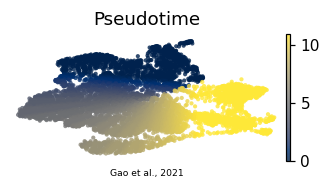

In [8]:
# sanitize non-serializable ElPiGraph uns entry (node positions kept; graph lives in uns['graph'])
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Gao et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')